# Chapter 3: Moving from pandas to Polars

In [1]:
import polars as pl
pl.__version__  # The book is built with Polars version 1.20.0

'2.0.0'

## Animals

In [2]:
pl.read_csv('data/animals.csv')

animal,class,habitat,diet,lifespan,status,features,weight
str,str,str,str,i64,str,str,i64
"""dolphin""","""mammal""","""oceans/rivers""","""carnivore""",40,"""least concern""","""high intelligence""",150
"""duck""","""bird""","""wetlands""","""omnivore""",8,"""least concern""","""waterproof feathers""",3
"""elephant""","""mammal""","""savannah""","""herbivore""",60,"""endangered""","""large ears and trunk""",8000
"""ibis""","""bird""","""wetlands""","""omnivore""",16,"""least concern""","""long, curved bill""",1
"""impala""","""mammal""","""savannah""","""herbivore""",12,"""least concern""","""long, curved horns""",70
"""kudu""","""mammal""","""savannah""","""herbivore""",15,"""least concern""","""spiral horns""",250
"""narwhal""","""mammal""","""arctic ocean""","""carnivore""",40,"""near threatened""","""long, spiral tusk""",null
"""panda""","""mammal""","""forests""","""herbivore""",20,"""vulnerable""","""black and white coloration""",100
"""polar bear""","""mammal""","""arctic""","""carnivore""",25,"""vulnerable""","""thick fur and blubber""",720


## Similarities to Recognize

## Appearances to Appreciate

In [4]:
import pandas as pd
import polars as pl

### Differences in Code

In [7]:
animals_pd = pd.read_csv("data/animals.csv", sep=",", header=0, dtype_backend='numpy_nullable')
animals_pl = pl.read_csv("data/animals.csv", separator=",", has_header=True)

print(f"{type(animals_pd) = }")
print(f"{type(animals_pl) = }")

type(animals_pd) = <class 'pandas.DataFrame'>
type(animals_pl) = <class 'polars.dataframe.frame.DataFrame'>


### Differences in Display

In [8]:
animals_pd

,animal,class,habitat,diet,lifespan,status,features,weight
0,dolphin,mammal,oceans/rivers,carnivore,40,least concern,high intelligence,150
1,duck,bird,wetlands,omnivore,8,least concern,waterproof feathers,3
2,elephant,mammal,savannah,herbivore,60,endangered,large ears and trunk,8000
3,ibis,bird,wetlands,omnivore,16,least concern,"long, curved bill",1
4,impala,mammal,savannah,herbivore,12,least concern,"long, curved horns",70
5,kudu,mammal,savannah,herbivore,15,least concern,spiral horns,250
6,narwhal,mammal,arctic ocean,carnivore,40,near threatened,"long, spiral tusk",<NA>
7,panda,mammal,forests,herbivore,20,vulnerable,black and white coloration,100
8,polar bear,mammal,arctic,carnivore,25,vulnerable,thick fur and blubber,720
9,ray,fish,oceans,carnivore,20,<NA>,"flat, disc-shaped body",90


In [9]:
animals_pd.dtypes

animal      string
class       string
habitat     string
diet        string
lifespan     Int64
status      string
features    string
weight       Int64
dtype: object

In [8]:
animals_pl

animal,class,habitat,diet,lifespan,status,features,weight
str,str,str,str,i64,str,str,i64
"""dolphin""","""mammal""","""oceans/rivers""","""carnivore""",40,"""least concern""","""high intelligence""",150
"""duck""","""bird""","""wetlands""","""omnivore""",8,"""least concern""","""waterproof feathers""",3
"""elephant""","""mammal""","""savannah""","""herbivore""",60,"""endangered""","""large ears and trunk""",8000
"""ibis""","""bird""","""wetlands""","""omnivore""",16,"""least concern""","""long, curved bill""",1
"""impala""","""mammal""","""savannah""","""herbivore""",12,"""least concern""","""long, curved horns""",70
"""kudu""","""mammal""","""savannah""","""herbivore""",15,"""least concern""","""spiral horns""",250
"""narwhal""","""mammal""","""arctic ocean""","""carnivore""",40,"""near threatened""","""long, spiral tusk""",null
"""panda""","""mammal""","""forests""","""herbivore""",20,"""vulnerable""","""black and white coloration""",100
"""polar bear""","""mammal""","""arctic""","""carnivore""",25,"""vulnerable""","""thick fur and blubber""",720


In [9]:
animals_pd["animal"]

0       dolphin
1          duck
2      elephant
3          ibis
4        impala
5          kudu
6       narwhal
7         panda
8    polar bear
9           ray
Name: animal, dtype: str

In [10]:
animals_pl.get_column("animal")

animal
str
"""dolphin"""
"""duck"""
"""elephant"""
"""ibis"""
"""impala"""
"""kudu"""
"""narwhal"""
"""panda"""
"""polar bear"""


In [11]:
animals_pd = animals_pd.drop(columns=["habitat", "diet", "features"])
animals_pd

,animal,class,lifespan,status,weight
0,dolphin,mammal,40,least concern,150.0
1,duck,bird,8,least concern,3.0
2,elephant,mammal,60,endangered,8000.0
3,ibis,bird,16,least concern,1.0
4,impala,mammal,12,least concern,70.0
5,kudu,mammal,15,least concern,250.0
6,narwhal,mammal,40,near threatened,NaN
7,panda,mammal,20,vulnerable,100.0
8,polar bear,mammal,25,vulnerable,720.0
9,ray,fish,20,NaN,90.0


In [12]:
price = pl.Series([10, 11, 12, 11, 15])

ema = price.ewm_mean(alpha=0.5, adjust=False)

print(ema)

shape: (5,)
Series: '' [f64]
[
	10.0
	10.5
	11.25
	11.125
	13.0625
]


In [13]:
animals_pl = animals_pl.drop("habitat", "diet", "features")
animals_pl

animal,class,lifespan,status,weight
str,str,i64,str,i64
"""dolphin""","""mammal""",40,"""least concern""",150
"""duck""","""bird""",8,"""least concern""",3
"""elephant""","""mammal""",60,"""endangered""",8000
"""ibis""","""bird""",16,"""least concern""",1
"""impala""","""mammal""",12,"""least concern""",70
"""kudu""","""mammal""",15,"""least concern""",250
"""narwhal""","""mammal""",40,"""near threatened""",null
"""panda""","""mammal""",20,"""vulnerable""",100
"""polar bear""","""mammal""",25,"""vulnerable""",720


## Concepts to Unlearn

### Index

In [14]:
animals_pd.index

RangeIndex(start=0, stop=10, step=1)

In [15]:
animals_agg_pd = animals_pd.groupby(["class", "status"])[["weight"]].mean()
animals_agg_pd

weight
class  status                      
bird   least concern       2.000000
mammal endangered       8000.000000
       least concern     156.666667
       near threatened          NaN
       vulnerable        410.000000

In [16]:
animals_agg_pd.index

MultiIndex([(  'bird',   'least concern'),
            ('mammal',      'endangered'),
            ('mammal',   'least concern'),
            ('mammal', 'near threatened'),
            ('mammal',      'vulnerable')],
           names=['class', 'status'])

In [17]:
animals_agg_pd.reset_index()

,class,status,weight
0,bird,least concern,2.000000
1,mammal,endangered,8000.000000
2,mammal,least concern,156.666667
3,mammal,near threatened,NaN
4,mammal,vulnerable,410.000000


In [18]:
%timeit animals_pl.group_by(["class", "status"]).agg(pl.col("weight").mean())

207 μs ± 16.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [19]:
%timeit animals_pd.groupby(["class", "status"]).agg({"weight": "mean"})

1.66 ms ± 50 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


### Axes

In [ ]:
# This raises a KeyError:
# animals_pd.drop("weight")

In [20]:
try:
    animals_pd.drop('weight', axis=0)
except Exception as e:
    print(f"Error: {e}")
finally:
    animals_pd.drop("weight", axis=1)

Error: "['weight'] not found in axis"


### Indexing and Slicing

In [21]:
animals_pd[["animal", "class"]]

,animal,class
0,dolphin,mammal
1,duck,bird
2,elephant,mammal
3,ibis,bird
4,impala,mammal
5,kudu,mammal
6,narwhal,mammal
7,panda,mammal
8,polar bear,mammal
9,ray,fish


In [22]:
animals_pd[animals_pd["status"] == "endangered"]

,animal,class,lifespan,status,weight
2,elephant,mammal,60,endangered,8000.0


In [23]:
animals_pd[:3]

,animal,class,lifespan,status,weight
0,dolphin,mammal,40,least concern,150.0
1,duck,bird,8,least concern,3.0
2,elephant,mammal,60,endangered,8000.0


In [24]:
animals_pd["weight"] = animals_pd["weight"] * 1000

In [25]:
animals_pd["weight"]

0     150000.0
1       3000.0
2    8000000.0
3       1000.0
4      70000.0
5     250000.0
6          NaN
7     100000.0
8     720000.0
9      90000.0
Name: weight, dtype: float64

In [28]:
animals_pd["weight"] = animals_pd["weight"].sort_values().reset_index(drop=True)

In [29]:
animals_pd["weight"]

0       1000.0
1       3000.0
2      70000.0
3      90000.0
4     100000.0
5     150000.0
6     250000.0
7     720000.0
8    8000000.0
9          NaN
Name: weight, dtype: float64

### Eagerness

In [30]:
lazy_query = (
    pl.scan_csv("data/animals.csv")
    .group_by("class")
    .agg(pl.col("weight").mean())
    .filter(pl.col("class") == "mammal")
)

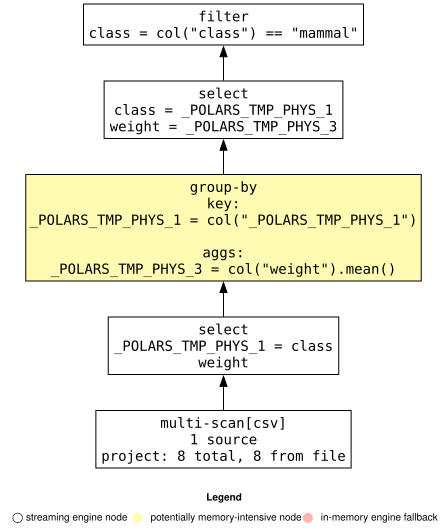

In [31]:
lazy_query.show_graph(optimized=False)

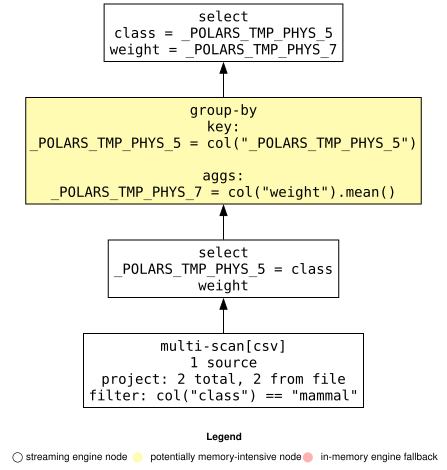

In [32]:
lazy_query.show_graph()

In [33]:
lazy_query.collect()

class,weight
str,f64
"""mammal""",1548.333333


In [38]:
df = pd.DataFrame(
    {"A_int": [1, 2, 3, 4, 5, None, 6]},
)

print(df.dtypes)

A_int    float64
dtype: object


### Relaxedness

## Syntax to Forget

### Common Operations Side By Side

#### Removing duplicate values

In [1]:
import polars as pl
import pandas as pd

In [3]:
animals_pd.drop_duplicates(subset="class")

,animal,class,habitat,diet,lifespan,status,features,weight
0,dolphin,mammal,oceans/rivers,carnivore,40,least concern,high intelligence,150.0
1,duck,bird,wetlands,omnivore,8,least concern,waterproof feathers,3.0
9,ray,fish,oceans,carnivore,20,NaN,"flat, disc-shaped body",90.0


In [4]:
animals_pl.unique(subset="class")

animal,class,habitat,diet,lifespan,status,features,weight
str,str,str,str,i64,str,str,i64
"""dolphin""","""mammal""","""oceans/rivers""","""carnivore""",40,"""least concern""","""high intelligence""",150
"""ray""","""fish""","""oceans""","""carnivore""",20,"""""","""flat, disc-shaped body""",90
"""duck""","""bird""","""wetlands""","""omnivore""",8,"""least concern""","""waterproof feathers""",3


#### Removing missing values

In [10]:
animals_pd.dropna(subset="weight")

,animal,class,habitat,diet,lifespan,status,features,weight
0,dolphin,mammal,oceans/rivers,carnivore,40,least concern,high intelligence,150
1,duck,bird,wetlands,omnivore,8,least concern,waterproof feathers,3
2,elephant,mammal,savannah,herbivore,60,endangered,large ears and trunk,8000
3,ibis,bird,wetlands,omnivore,16,least concern,"long, curved bill",1
4,impala,mammal,savannah,herbivore,12,least concern,"long, curved horns",70
5,kudu,mammal,savannah,herbivore,15,least concern,spiral horns,250
7,panda,mammal,forests,herbivore,20,vulnerable,black and white coloration,100
8,polar bear,mammal,arctic,carnivore,25,vulnerable,thick fur and blubber,720
9,ray,fish,oceans,carnivore,20,<NA>,"flat, disc-shaped body",90


In [11]:
animals_pl.drop_nulls(subset="weight")

animal,class,habitat,diet,lifespan,status,features,weight
str,str,str,str,i64,str,str,i64
"""dolphin""","""mammal""","""oceans/rivers""","""carnivore""",40,"""least concern""","""high intelligence""",150
"""duck""","""bird""","""wetlands""","""omnivore""",8,"""least concern""","""waterproof feathers""",3
"""elephant""","""mammal""","""savannah""","""herbivore""",60,"""endangered""","""large ears and trunk""",8000
"""ibis""","""bird""","""wetlands""","""omnivore""",16,"""least concern""","""long, curved bill""",1
"""impala""","""mammal""","""savannah""","""herbivore""",12,"""least concern""","""long, curved horns""",70
"""kudu""","""mammal""","""savannah""","""herbivore""",15,"""least concern""","""spiral horns""",250
"""panda""","""mammal""","""forests""","""herbivore""",20,"""vulnerable""","""black and white coloration""",100
"""polar bear""","""mammal""","""arctic""","""carnivore""",25,"""vulnerable""","""thick fur and blubber""",720
"""ray""","""fish""","""oceans""","""carnivore""",20,"""""","""flat, disc-shaped body""",90


#### Sorting rows

In [ ]:
animals_pd.sort_values("weight", ascending=False)

,animal,class,habitat,diet,lifespan,status,features,weight
2,elephant,mammal,savannah,herbivore,60,endangered,large ears and trunk,8000
8,polar bear,mammal,arctic,carnivore,25,vulnerable,thick fur and blubber,720
5,kudu,mammal,savannah,herbivore,15,least concern,spiral horns,250
0,dolphin,mammal,oceans/rivers,carnivore,40,least concern,high intelligence,150
7,panda,mammal,forests,herbivore,20,vulnerable,black and white coloration,100
9,ray,fish,oceans,carnivore,20,<NA>,"flat, disc-shaped body",90
4,impala,mammal,savannah,herbivore,12,least concern,"long, curved horns",70
1,duck,bird,wetlands,omnivore,8,least concern,waterproof feathers,3
3,ibis,bird,wetlands,omnivore,16,least concern,"long, curved bill",1
6,narwhal,mammal,arctic ocean,carnivore,40,near threatened,"long, spiral tusk",<NA>


In [14]:
animals_pl.sort("weight", descending=True, nulls_last=True)

animal,class,habitat,diet,lifespan,status,features,weight
str,str,str,str,i64,str,str,i64
"""elephant""","""mammal""","""savannah""","""herbivore""",60,"""endangered""","""large ears and trunk""",8000
"""polar bear""","""mammal""","""arctic""","""carnivore""",25,"""vulnerable""","""thick fur and blubber""",720
"""kudu""","""mammal""","""savannah""","""herbivore""",15,"""least concern""","""spiral horns""",250
"""dolphin""","""mammal""","""oceans/rivers""","""carnivore""",40,"""least concern""","""high intelligence""",150
"""panda""","""mammal""","""forests""","""herbivore""",20,"""vulnerable""","""black and white coloration""",100
"""ray""","""fish""","""oceans""","""carnivore""",20,"""""","""flat, disc-shaped body""",90
"""impala""","""mammal""","""savannah""","""herbivore""",12,"""least concern""","""long, curved horns""",70
"""duck""","""bird""","""wetlands""","""omnivore""",8,"""least concern""","""waterproof feathers""",3
"""ibis""","""bird""","""wetlands""","""omnivore""",16,"""least concern""","""long, curved bill""",1


#### Casting an existing column

In [16]:
animals_pd.assign(lifespan=animals_pd["lifespan"].astype(pd.Float64Dtype()))

,animal,class,habitat,diet,lifespan,status,features,weight
0,dolphin,mammal,oceans/rivers,carnivore,40.0,least concern,high intelligence,150
1,duck,bird,wetlands,omnivore,8.0,least concern,waterproof feathers,3
2,elephant,mammal,savannah,herbivore,60.0,endangered,large ears and trunk,8000
3,ibis,bird,wetlands,omnivore,16.0,least concern,"long, curved bill",1
4,impala,mammal,savannah,herbivore,12.0,least concern,"long, curved horns",70
5,kudu,mammal,savannah,herbivore,15.0,least concern,spiral horns,250
6,narwhal,mammal,arctic ocean,carnivore,40.0,near threatened,"long, spiral tusk",<NA>
7,panda,mammal,forests,herbivore,20.0,vulnerable,black and white coloration,100
8,polar bear,mammal,arctic,carnivore,25.0,vulnerable,thick fur and blubber,720
9,ray,fish,oceans,carnivore,20.0,<NA>,"flat, disc-shaped body",90


In [17]:
animals_pl.with_columns(pl.col("lifespan").cast(pl.Float64))

animal,class,habitat,diet,lifespan,status,features,weight
str,str,str,str,f64,str,str,i64
"""dolphin""","""mammal""","""oceans/rivers""","""carnivore""",40.0,"""least concern""","""high intelligence""",150
"""duck""","""bird""","""wetlands""","""omnivore""",8.0,"""least concern""","""waterproof feathers""",3
"""elephant""","""mammal""","""savannah""","""herbivore""",60.0,"""endangered""","""large ears and trunk""",8000
"""ibis""","""bird""","""wetlands""","""omnivore""",16.0,"""least concern""","""long, curved bill""",1
"""impala""","""mammal""","""savannah""","""herbivore""",12.0,"""least concern""","""long, curved horns""",70
"""kudu""","""mammal""","""savannah""","""herbivore""",15.0,"""least concern""","""spiral horns""",250
"""narwhal""","""mammal""","""arctic ocean""","""carnivore""",40.0,"""near threatened""","""long, spiral tusk""",null
"""panda""","""mammal""","""forests""","""herbivore""",20.0,"""vulnerable""","""black and white coloration""",100
"""polar bear""","""mammal""","""arctic""","""carnivore""",25.0,"""vulnerable""","""thick fur and blubber""",720


#### Aggregating rows

In [20]:
animals_pd.groupby(["class", "status"], as_index=False)[["weight"]].mean()

,class,status,weight
0,bird,least concern,2.0
1,mammal,endangered,8000.0
2,mammal,least concern,156.666667
3,mammal,near threatened,<NA>
4,mammal,vulnerable,410.0


In [22]:
animals_pl.group_by("class", "status").agg(pl.col("weight").mean())

class,status,weight
str,str,f64
"""mammal""","""near threatened""",null
"""bird""","""least concern""",2.0
"""mammal""","""endangered""",8000.0
"""mammal""","""vulnerable""",410.0
"""mammal""","""least concern""",156.666667
"""fish""","""""",90.0


## To and From pandas

In [ ]:
animals_pl = pl.DataFrame(animals_pd)

animals_pl

In [ ]:
there_and_back_again_df = animals_pl.to_pandas()

there_and_back_again_df

## Takeaways